# 9. Truly ungauged: stock tanks and farm ponds

Notebook 8 mapped small reservoirs as if they had no gauge, but they did have one, and it did
the scoring. The water that really has no gauge in Texas is much smaller: hundreds of thousands
of **stock tanks and farm ponds**, mostly under a few acres. Nobody records their level, so
there is nothing to compare a satellite map against.

This notebook swaps the gauge for **independent imagery**. USDA's NAIP program flies aerial
photography over Texas every two years at 0.6 m, with a near-infrared band. A 1-acre pond is
about 11,000 NAIP pixels, against 40 Sentinel-2 pixels. On each NAIP flight date we outline
water from the photo and compare it with satellite maps from the nearest days.

As in notebook 8, everything on the satellite side is used **unchanged**: the shipped models,
trained only on the Highland Lakes, and index cutoffs tuned there.

What the test asks:

1. **Detection.** Does a method find a pond at all?
2. **Area.** How much of the pond does it map?
3. **False alarms.** Does it invent water on dry tanks and dry land?

In [1]:
from hlw.nb import setup

setup()
import json

import pandas as pd
from IPython.display import Image, display

from hlw import ponds as P

cfg = P.pcfg()
pd.DataFrame([{"site": v["name"], "lon, lat": f"{v['point'][0]:.2f}, {v['point'][1]:.2f}",
               "ponds": len(pd.read_csv(P.P_DIR / k / "ponds.csv"))}
              for k, v in P.sites().items()])

,site,"lon, lat",ponds
0,Rolling Plains (Throckmorton Co.),"-99.25, 33.10",78
1,Cross Timbers (Erath Co.),"-98.30, 32.30",92
2,Concho Valley (Coke Co.),"-100.45, 31.85",70
3,Edwards Plateau (Menard Co.),"-99.70, 30.80",9
4,Blackland Prairie (Falls Co.),"-96.95, 31.15",54
5,Post Oak Savannah (Lee Co.),"-96.95, 30.30",144
6,South Texas brush (McMullen Co.),"-98.70, 28.25",10
7,High Plains playas (Hale Co.),"-101.70, 34.10",4


## Sites

Eight 5 km × 5 km boxes in ranch and farm country, spread across the state's landscapes:
Rolling Plains, Cross Timbers, Concho Valley, Edwards Plateau, Blackland Prairie, Post Oak
Savannah, South Texas brush and the High Plains. They were chosen by landscape before any water
map was made. One box was moved, for a reason worth knowing. The first South Texas box landed
on an oil refinery, a town and a river corridor, which is not stock-tank country. Refinery
shadows also passed the water test, as the next section explains. It was moved to brush country
before any satellite comparison was looked at there.

Pond counts vary a lot: Post Oak and Cross Timbers are dotted with tanks, while the Edwards
Plateau box (thin soils over limestone) has almost none.

## Building the reference, and checking it

The NAIP water rule is simple:

* **Water index.** Green vs NIR (NDWI) above 0.2, grown through connected pixels above 0.1.
* **NIR darkness.** NIR below a fraction of red. Water absorbs NIR far more strongly than red.
* **Shape.** Bodies must be at least 200 m² and have a core at least 8 m wide, which removes
  thin tree-line and creek-bank shadows, and they must not be long strips.

Each rule earned its place by failing without it:

* **Shape filter.** The first version outlined every shadow along a creek.
* **NIR/red rule.** The 2022 photos at two sites marked whole plowed fields as water. NAIP isn't
  radiometrically calibrated, and in those flights bright bare soil reached NDWI 0.1-0.2.
* **Built-up mask.** Refinery shadows and dark roofs passed every rule, so built-up land (ESA
  WorldCover) is masked at every site.

A reference has to be checked like anything else. We drew 60 reference ponds at random, 20 in
each of three size classes, and judged each outline from the aerial photo, twice: first by the
AI labeller (Claude Opus 5.5), then by the author in a browser tool (`labels/tool/ponds.html`) that hid the
sizes and the AI's answers. Each outline got Water, Partly water, Not water or Unsure, plus a
flag when the line missed water of the same pond.

In [2]:
cmp = pd.read_csv(P.OUT / "audit_compare.csv")
pd.crosstab(cmp.water_ai, cmp.water_human, margins=True).rename_axis(index="AI", columns="author")

author,unsure,yes,All
AI,,,
no,0,1,1
partly,1,4,5
unsure,0,11,11
yes,0,43,43
All,1,59,60


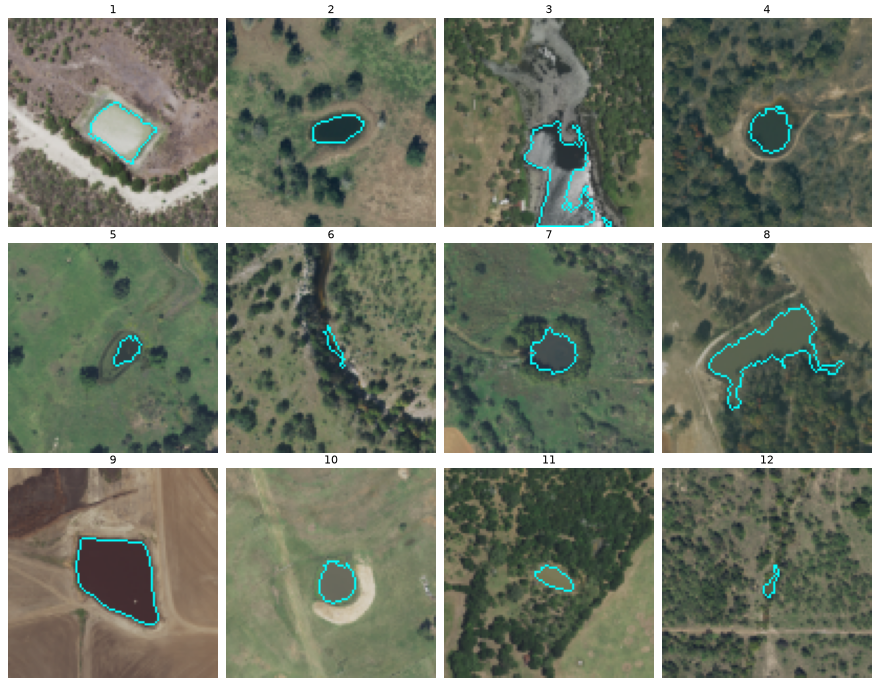

In [3]:
display(Image(filename=str(P.AUDIT_DIR / "sheet_01.png"), width=900))

The two checks agree wherever both committed, but they differ on doubt. The AI marked 11
outlines unsure and 6 as partly or not water, mostly small dark patches in brush that it
thought could be shadow. **The author called 59 of 60 plainly water**, in every size class; the
one unsure (#18) is a pond half-hidden by sun glint. So the reference outlines are trustworthy
down to the smallest ponds, and the AI's doubt about them was its own uncertainty, not a fault
in the reference. It is the same lesson as notebook 6: a second, human look moved the answer.

A closer look shows one weakness the yes/no question can't see: in two ponds (#3, #18) part of
the water is a sheet of sun glint, which the NDWI rule doesn't call water, so the outline is too small. Glint, and
split outlines like #41, make the reference area run a little low.

The **headline numbers still use ponds of at least 0.25 acre**, but now for a different
reason: that is about ten Sentinel-2 pixels, and below it every method mostly misses. (NDWI
still finds 27 % of the smaller ponds, against 1 % for the U-Net.)

The reference has a known blind spot too. A pond covered in duckweed or algae reflects NIR
like a field, and the rule doesn't call it water. Neither would a satellite index. The test
measures **open water**.

## Matching dates

Ponds change, so the satellite day must be close to the flight. We map every clear Sentinel-2
day within ±10 days of each NAIP flight, and every Sentinel-1 day within ±6 days, then score
the **nearest** one. The median gap is 1 day for Sentinel-2 and 3 days for Sentinel-1.

Each pond is scored inside its footprint: the NAIP outline plus 20 m around it. Mixed edge
pixels and small misregistration then count toward the pond. "Detected" means at least one
10 m pixel called water inside that footprint.

Detection needs a **chance baseline**. A noisy method that scatters water pixels everywhere
will "detect" many ponds by luck. So every footprint is also moved about 650 m onto land with
no NAIP water, and the same test is run there.

In [4]:
s = json.loads((P.OUT / "summary.json").read_text())
print("flights:", s["flights"], " ponds:", s["ponds"], " median gap (days):",
      s["median_abs_gap_days"])
t = pd.read_csv(P.OUT / "summary_by_method.csv", index_col=0)
cols = {"n_wet_ge025ac": "wet ponds (≥0.25 ac)", "detected_pct_ge025ac": "detected %",
        "chance_detected_pct_ge025ac": "chance %", "detected_pct_ge1ac": "detected % (≥1 ac)",
        "total_bias_pct_ge025ac": "total area error %", "false_alarm_pct": "dry tanks flagged %",
        "false_blobs_per_km2": "false blobs per km²"}
t[list(cols)].rename(columns=cols).round(1)

flights: 26  ponds: 461  median gap (days): {'s1': 3.0, 's2': 1.0}


,wet ponds (≥0.25 ac),detected %,chance %,detected % (≥1 ac),total area error %,dry tanks flagged %,false blobs per km²
method,,,,,,,
MNDWI (0),340.0,22.6,0.0,55.9,-61.7,5.8,0.1
MNDWI (HL cutoff),340.0,37.1,0.0,66.1,-52.9,11.0,0.4
NDWI (0),340.0,69.7,0.0,76.3,-43.7,6.0,0.1
NDWI (HL cutoff),340.0,74.1,0.0,81.4,-40.3,7.4,0.2
S1 U-Net,395.0,16.2,1.2,61.6,-51.3,1.9,0.5
S1 U-Net (expected area),395.0,NaN,NaN,NaN,-41.1,NaN,0.0
S2 U-Net,340.0,19.1,0.0,71.2,-57.5,1.6,0.0
S2 U-Net (expected area),340.0,NaN,NaN,NaN,-51.9,NaN,0.0
SCL water,340.0,8.2,0.0,33.9,-75.6,1.0,0.0


## Results

Read the table one row at a time:

* **NDWI** (green vs NIR, both 10 m bands) is the clear winner for small ponds. With the
  cutoff tuned on the Highland Lakes points (−0.025) it finds **74 %** of ponds of 0.25 acre
  or more; with the textbook cutoff of 0 it finds 70 %. Either way it adds almost no false
  water.
* The **S2 U-Net** finds **19 %**. Above 1 acre it reaches 71 %, and above 2 acres it catches
  up with NDWI.
* **MNDWI** finds 37 % with its Highland Lakes cutoff (−0.14) and 23 % at 0. Its SWIR band is
  20 m, so a pond a few pixels wide blurs into its surroundings before the index is computed.
* **The SCL water class** finds 8 %.
* **The radar threshold** (VV) appears to find 99 %. Its chance rate is 85 %, and it scatters
  about 150 false blobs per km². Those "detections" are mostly speckle.
* **The S1 U-Net** is clean (about 1 % chance) but finds only 16 %.

Is NDWI's lead consistent across sites, or driven by one?

In [5]:
b = pd.read_csv(P.OUT / "by_site.csv")
b[b.method.isin(["NDWI (0)", "S2 U-Net", "MNDWI (HL cutoff)", "S1 U-Net"])].pivot(
    index="site", columns="method", values="detected_pct").round(0)

method,MNDWI (HL cutoff),NDWI (0),S1 U-Net,S2 U-Net
site,,,,
blackland_prairie,33.0,44.0,0.0,8.0
concho_valley,37.0,73.0,22.0,39.0
cross_timbers,38.0,74.0,15.0,16.0
high_plains,50.0,50.0,83.0,50.0
post_oak,25.0,68.0,13.0,5.0
rolling_plains,39.0,72.0,19.0,27.0
south_texas,100.0,100.0,20.0,40.0


NDWI > 0 finds more ponds than the U-Net at 6 of the 7 sites with ponds of that size, and ties
at the seventh (sign test p = 0.03). The tuned NDWI cutoff gives the same pattern. Edwards
Plateau has none that big.

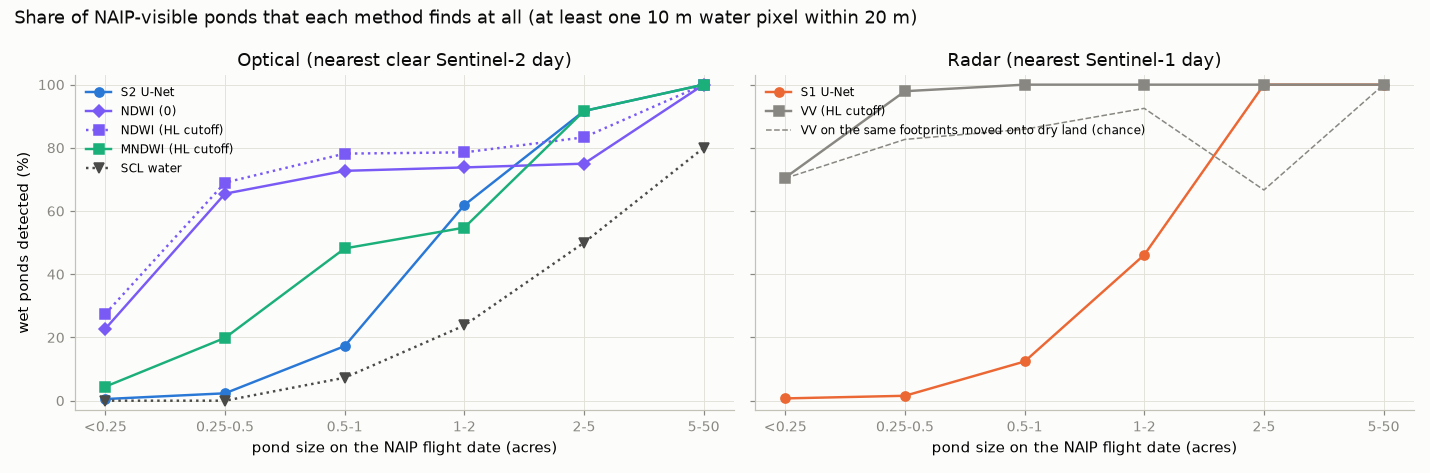

In [6]:
display(Image(filename=str(P.OUT / "ponds_detection.png"), width=1100))

Detection against pond size makes the pattern plain:

* **Below about 2 acres**, NDWI is the only method that finds most ponds.
* **Above 2 acres**, the U-Net and MNDWI catch up.
* The **tuned NDWI cutoff** (−0.025) and plain 0 behave almost the same. The cutoff tuned on
  big Highland Lakes shorelines carried straight over to ponds. (Tuned on the AI labels,
  the cutoff is 0.23 and finds far fewer ponds; see notebook 4 for why.)

The radar threshold's line sits only 8-33 points above its own chance line, which is much less
than its raw rate suggests. For the smallest ponds it matches chance (71 % vs 70 %).

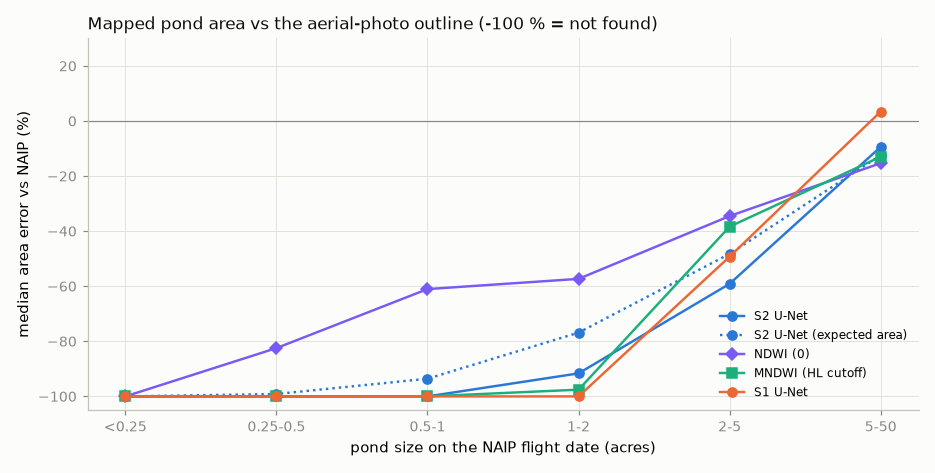

In [7]:
display(Image(filename=str(P.OUT / "ponds_area_error.png"), width=800))

## Area: everyone under-counts

Even when a pond is found, its area is short. NDWI > 0 maps 44 % less pond area than NAIP in
total (ponds of 0.25 acre or more). For a 1-2 acre pond, the median is 57 % short.

This isn't a quirk of one method. It is the **mixed-pixel problem**. A 1-acre pond is about 40
Sentinel-2 pixels, and around half of them touch the shore. Each edge pixel is part water and
part bank, and a threshold calls most of them land.

The U-Net's expected area (summing probabilities rather than thresholding) recovers some of
the loss, but not enough. Above 5 acres, errors fall to the 10-20 % range seen on the small
reservoirs in notebook 8.

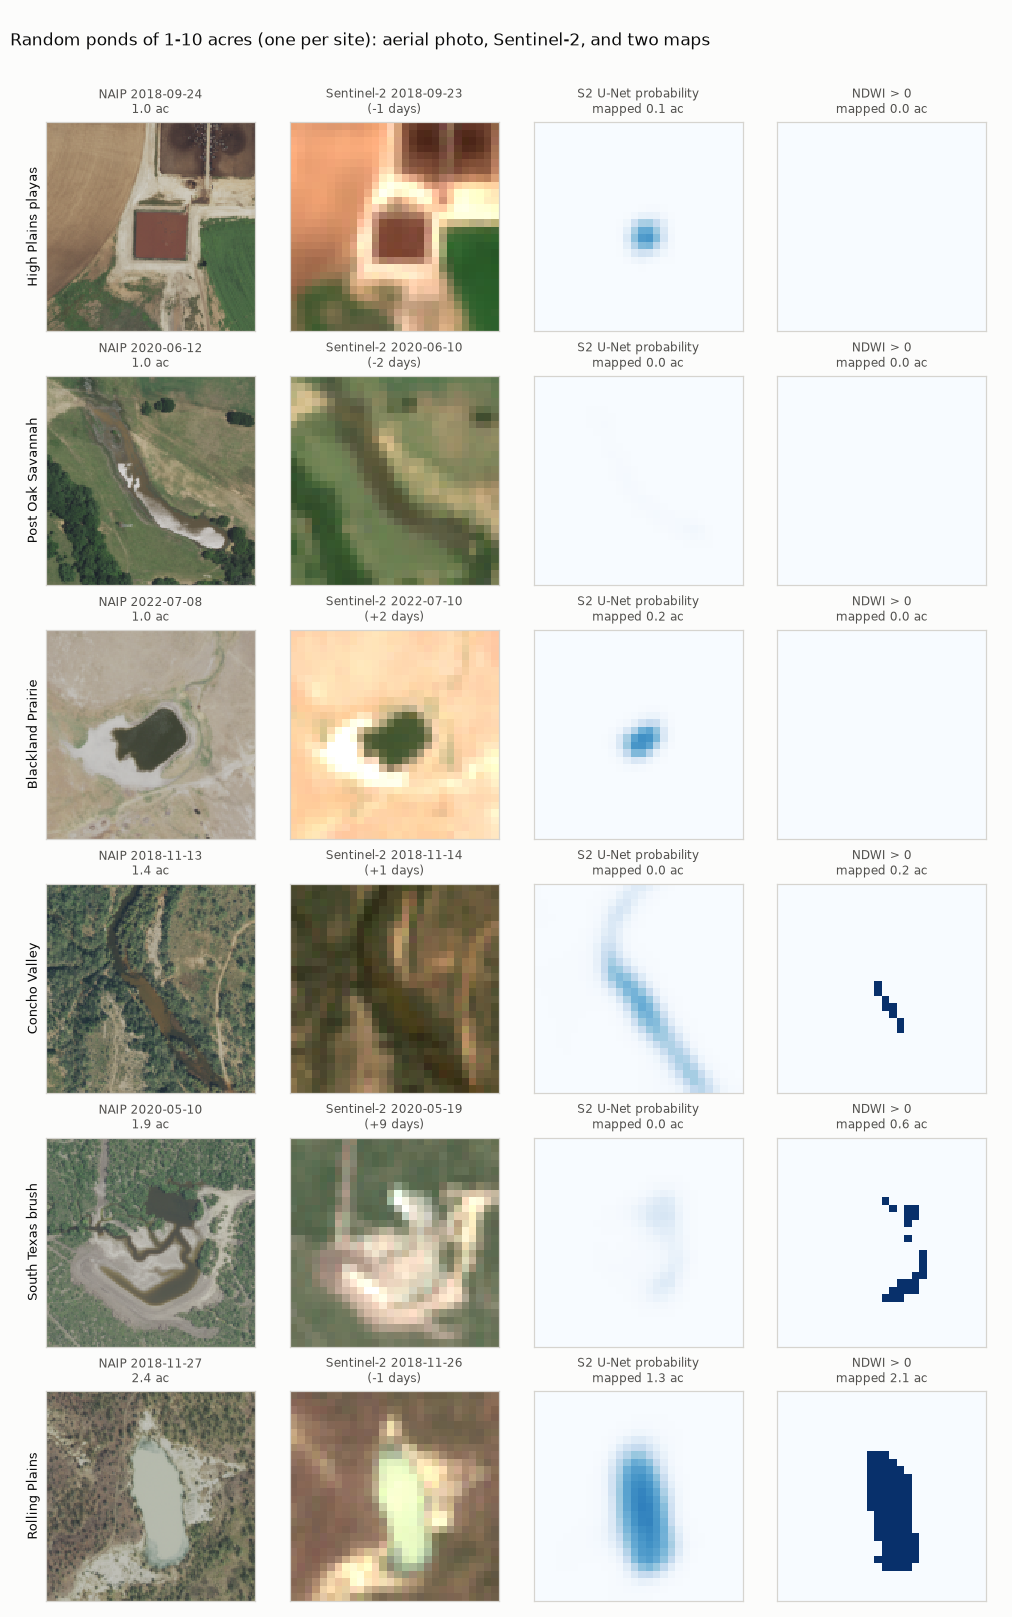

In [8]:
display(Image(filename=str(P.OUT / "ponds_gallery.png"), width=900))

These are random ponds of 1-10 acres, one per site. They show the cases behind the averages:

* **Clear wins for NDWI.** A pale turbid tank (Rolling Plains), and a half-dry pond that NDWI
  partly finds (South Texas).
* **Misses by both.** A red feedlot lagoon (High Plains), and a dry, white-crusted creek tank
  (Post Oak).
* **A win for the U-Net.** A dark green tank (Blackland Prairie) that the U-Net picks up and
  NDWI misses.
* **A creek pool.** NAIP counts the water in a creek bed (Concho Valley). Arguably it isn't a
  pond at all.

## Why the model that won on reservoirs loses on ponds

On the small reservoirs (notebook 8), the U-Net had an edge over NDWI that grew as lakes got
smaller. On ponds the trend reverses sharply, and NDWI wins by a wide margin. Two reasons:

1. **Scale it never saw.** The smallest water body in its training data was a lake arm tens
   of pixels wide. A pond 5 pixels across, surrounded by grass, is out of distribution. Its
   output for such ponds is a faint, smooth blob (probability 0.1-0.6) that rarely clears 0.5.
   The water is visible in the image, but the model doesn't commit.
2. **Resolution in the inputs.** The model and MNDWI both lean on 20 m SWIR bands, which are
   excellent for big turbid lakes. NDWI uses only 10 m bands, and at this scale sharpness
   beats spectral cleverness.

Neither reason means deep learning can't map ponds. They say this model, trained on these
lakes, shouldn't be trusted on ponds without training data that includes them. NAIP itself is
a source of exactly such labels.

## What this does and doesn't show

**Shown:**

* For **stock tanks under about 2 acres**, plain NDWI > 0 on Sentinel-2 finds about 70 % of
  ponds of 0.25 acre or more, with almost no false water. It is better than the shipped U-Net
  at every site where they differ.
* **No method measures small-pond area well.** Mixed pixels cost roughly half the area of a
  1-2 acre pond. Satellite area for ponds this size is an index of wetness, not acreage.
* **Radar is not a fix for small ponds.** The VV threshold is mostly speckle, and the S1 U-Net
  finds few ponds under 2 acres.

**Not shown, or caveats:**

* **The reference is a photo outline, not a survey.** The author's check of 60 outlines found
  59 plainly water and one unsure. It tests what is inside the line; sun glint can make the
  line too small.
* **The built-up mask drops farmstead ponds** within 50 m of buildings, which are common.
* **One flight per site every two years.** This tests snapshots, not time series. Whether a
  method tracks a pond's rise and fall month to month is still open.
* **Eight sites in one state.** Results may differ where ponds are clearer, larger or more
  vegetated.

**General takeaways:**

* **No gauge doesn't mean no test.** A finer independent sensor can be the reference, but check
  it as hard as the thing it tests. Here that meant three rule fixes, a moved site and a
  60-pond audit.
* **Detection needs a chance baseline.** A noisy method can "find" most targets by luck.
* **A model's win at one scale says little about the next scale down.**